# AI-Based Hospital Readmission Prediction System

# Exploratory Data Analysis (EDA)

# Objective

 The objective of this notebook is to perform Exploratory Data Analysis (EDA)
 on the hospital diabetes dataset.

# EDA helps us understand:
 - Patient demographics
 - Hospital stay patterns
 - Previous healthcare visits
 - Medication usage
 - Number of diagnoses
  - Relationship between features and 30-day readmission

# Important Note

 The observations obtained from EDA describe patterns and associations
 in the dataset. They should not be interpreted as causal relationships.

# Import Libraries

In [3]:
# Import pandas for data manipulation and data analysis
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib for creating basic visualizations
import matplotlib.pyplot as plt

# Import seaborn for advanced statistical visualizations
import seaborn as sns

# Display matplotlib plots directly inside the Jupyter Notebook
%matplotlib inline

# Set a clean default figure size for visualizations
plt.rcParams["figure.figsize"] = (8, 5)

# Set seaborn theme for better readability of plots
sns.set_theme(style="whitegrid")

# Confirm successful library import
print("All required libraries imported successfully.")

All required libraries imported successfully.


# Load Dataset

In [4]:
# Load the original hospital diabetes dataset
df = pd.read_csv("diabetic_data.csv")

# Replace '?' values with NaN so missing values can be handled correctly
df = df.replace("?", np.nan)

# Display the first five rows to verify that the dataset loaded correctly
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


# Check Dataset Shape

In [5]:
# Display the number of rows and columns in the dataset
print("Number of Rows:", df.shape[0])

# Display the number of columns in the dataset
print("Number of Columns:", df.shape[1])

Number of Rows: 101766
Number of Columns: 50


# Create Binary Target

In [6]:
# Create a new binary target column for 30-day readmission prediction
# '<30' represents patients readmitted within 30 days
# '>30' and 'NO' are treated as patients not readmitted within 30 days

df["readmitted_binary"] = (df["readmitted"] == "<30").astype(int)

# Display the original target and newly created binary target
df[["readmitted", "readmitted_binary"]].head(10)

,readmitted,readmitted_binary
0,NO,0
1,>30,0
2,NO,0
3,NO,0
4,NO,0
5,>30,0
6,NO,0
7,>30,0
8,NO,0
9,NO,0


# 1. Target Variable Analysis

The target variable represents whether a patient was readmitted within
30 days of discharge.

Binary target definition:

- 1 = Readmitted within 30 days
- 0 = Not readmitted within 30 days

In [7]:
# Count the number of patients in each target class
target_counts = df["readmitted_binary"].value_counts().sort_index()

# Display the number of patients in each class
print("Target Distribution:")
print(target_counts)

Target Distribution:
readmitted_binary
0    90409
1    11357
Name: count, dtype: int64


# Target Distribution Visualization

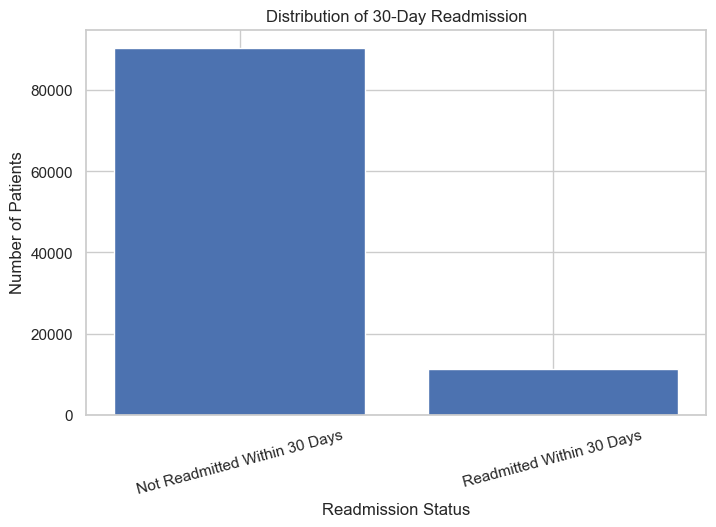

In [8]:
# Create readable labels for the binary target classes
target_labels = [
    "Not Readmitted Within 30 Days",
    "Readmitted Within 30 Days"
]

# Create a bar chart for the target distribution
plt.figure(figsize=(8, 5))

# Plot the number of patients for each target class
plt.bar(target_labels, target_counts.values)

# Add a title to the chart
plt.title("Distribution of 30-Day Readmission")

# Add label to the x-axis
plt.xlabel("Readmission Status")

# Add label to the y-axis
plt.ylabel("Number of Patients")

# Rotate x-axis labels for better readability
plt.xticks(rotation=15)

# Display the chart
plt.show()

# Target Percentage

In [9]:
# Calculate the percentage of patients in each target class
target_percentage = df["readmitted_binary"].value_counts(normalize=True) * 100

# Sort the target classes for consistent output
target_percentage = target_percentage.sort_index()

# Display the target percentage
print("Target Percentage:")

# Print the percentage of each target class
print(target_percentage.round(2))

Target Percentage:
readmitted_binary
0    88.84
1    11.16
Name: proportion, dtype: float64


# 2. Age Distribution

Age is an important patient-related feature.

The dataset stores age in ranges such as:
- [0-10)
- [10-20)
- [20-30)
- [30-40)
- [40-50)
- [50-60)
- [60-70)
- [70-80)
- [80-90)
- [90-100)

We will examine the distribution of patients across these age groups.

In [10]:
# Count the number of patients in each age group
age_counts = df["age"].value_counts().sort_index()

# Display the age group counts
print("Patients by Age Group:")
print(age_counts)

Patients by Age Group:
age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64


# Age Distribution Plot

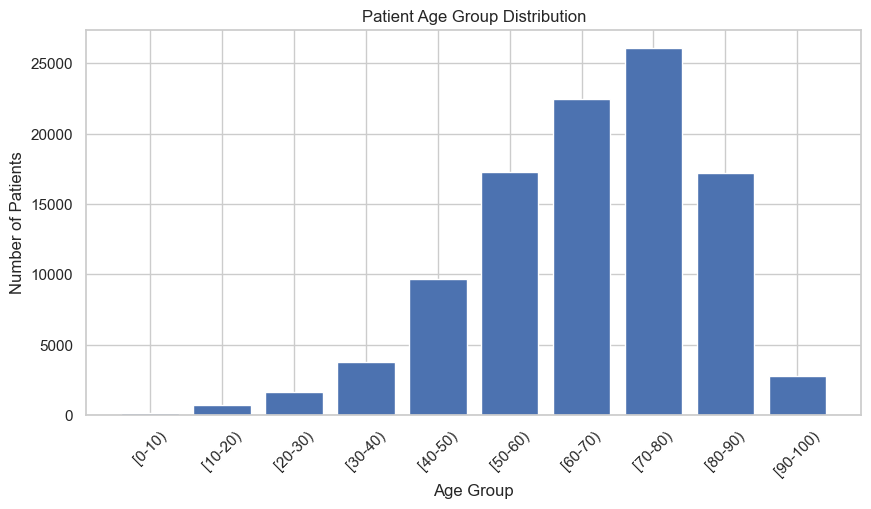

In [11]:
# Create a figure for the age distribution
plt.figure(figsize=(10, 5))

# Plot the number of patients in each age group
plt.bar(age_counts.index, age_counts.values)

# Add chart title
plt.title("Patient Age Group Distribution")

# Add x-axis label
plt.xlabel("Age Group")

# Add y-axis label
plt.ylabel("Number of Patients")

# Rotate age labels for better readability
plt.xticks(rotation=45)

# Display the chart
plt.show()

# Readmission Rate by Age

In [12]:
# Calculate the average binary readmission value for each age group
# Multiplying by 100 converts the value into a percentage
age_readmission_rate = (
    df.groupby("age")["readmitted_binary"].mean() * 100
)

# Display the readmission rate for each age group
print("30-Day Readmission Rate by Age Group:")
print(age_readmission_rate.round(2))

30-Day Readmission Rate by Age Group:
age
[0-10)       1.86
[10-20)      5.79
[20-30)     14.24
[30-40)     11.23
[40-50)     10.60
[50-60)      9.67
[60-70)     11.13
[70-80)     11.77
[80-90)     12.08
[90-100)    11.10
Name: readmitted_binary, dtype: float64


# Age vs Readmission Plot

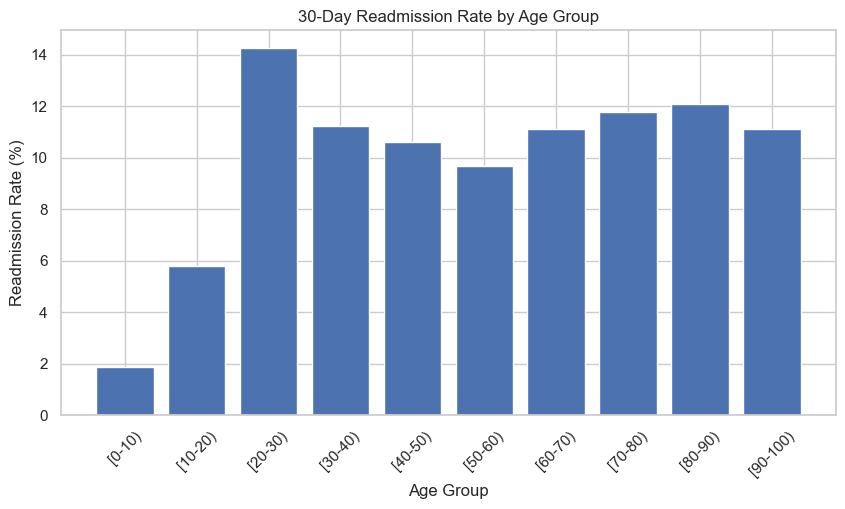

In [13]:
# Create a figure for the age-based readmission analysis
plt.figure(figsize=(10, 5))

# Plot the readmission rate for each age group
plt.bar(
    age_readmission_rate.index,
    age_readmission_rate.values
)

# Add chart title
plt.title("30-Day Readmission Rate by Age Group")

# Add x-axis label
plt.xlabel("Age Group")

# Add y-axis label
plt.ylabel("Readmission Rate (%)")

# Rotate age labels for readability
plt.xticks(rotation=45)

# Display the chart
plt.show()

# 3. Time in Hospital Analysis

The `time_in_hospital` variable represents the number of days
the patient stayed in the hospital.

We will analyze:
- Distribution of hospital stay
- Readmission rate by hospital stay
- Difference between readmission groups

# Hospital Stay Distribution

In [14]:
# Display descriptive statistics for hospital stay duration
print("Time in Hospital Statistics:")

# Calculate and display statistics such as mean, median and standard deviation
print(df["time_in_hospital"].describe())

Time in Hospital Statistics:
count    101766.000000
mean          4.395987
std           2.985108
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          14.000000
Name: time_in_hospital, dtype: float64


# Hospital Stay Histogram

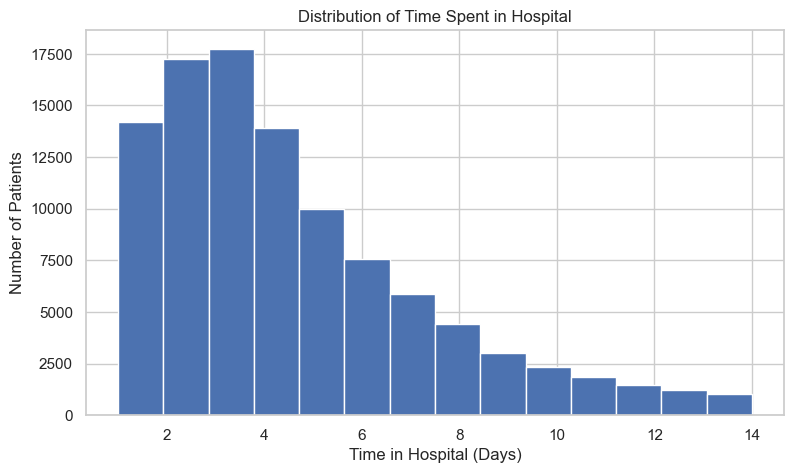

In [15]:
# Create a figure for hospital stay distribution
plt.figure(figsize=(9, 5))

# Plot a histogram of hospital stay duration
plt.hist(
    df["time_in_hospital"].dropna(),
    bins=14
)

# Add chart title
plt.title("Distribution of Time Spent in Hospital")

# Add x-axis label
plt.xlabel("Time in Hospital (Days)")

# Add y-axis label
plt.ylabel("Number of Patients")

# Display the chart
plt.show()

# Readmission Rate by Hospital Stay

In [16]:
# Calculate the average readmission rate for each hospital stay duration
stay_readmission_rate = (
    df.groupby("time_in_hospital")["readmitted_binary"].mean() * 100
)

# Display the calculated readmission rates
print("Readmission Rate by Hospital Stay:")
print(stay_readmission_rate.round(2))

Readmission Rate by Hospital Stay:
time_in_hospital
1      8.18
2      9.94
3     10.67
4     11.81
5     12.03
6     12.59
7     12.83
8     14.23
9     13.72
10    14.35
11    10.51
12    13.33
13    12.31
14    12.96
Name: readmitted_binary, dtype: float64


# Hospital Stay vs Readmission Plot

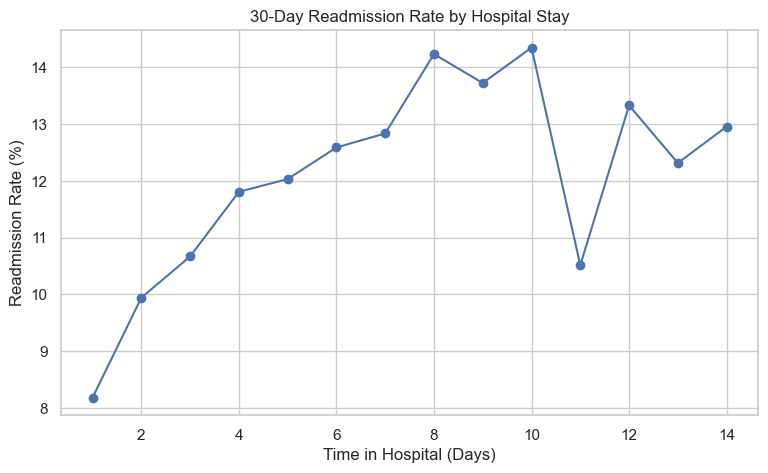

In [17]:
# Create a figure for the visualization
plt.figure(figsize=(9, 5))

# Plot hospital stay duration against readmission rate
plt.plot(
    stay_readmission_rate.index,
    stay_readmission_rate.values,
    marker="o"
)

# Add chart title
plt.title("30-Day Readmission Rate by Hospital Stay")

# Add x-axis label
plt.xlabel("Time in Hospital (Days)")

# Add y-axis label
plt.ylabel("Readmission Rate (%)")

# Display the chart
plt.show()

# Boxplot of Hospital Stay

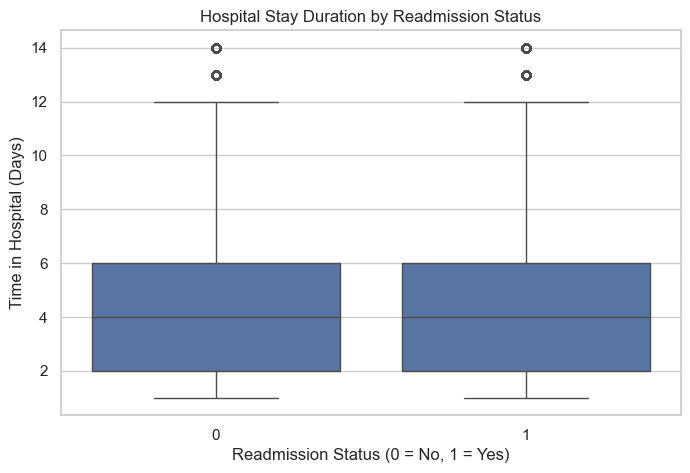

In [18]:
# Create a figure for comparing hospital stay between target classes
plt.figure(figsize=(8, 5))

# Create a boxplot using the binary readmission target
sns.boxplot(
    x="readmitted_binary",
    y="time_in_hospital",
    data=df
)

# Add chart title
plt.title("Hospital Stay Duration by Readmission Status")

# Add x-axis label
plt.xlabel("Readmission Status (0 = No, 1 = Yes)")

# Add y-axis label
plt.ylabel("Time in Hospital (Days)")

# Display the chart
plt.show()

# 4. Number of Diagnoses Analysis

The `number_diagnoses` variable represents the total number of diagnoses
recorded for a patient.

We will examine whether patients with different numbers of diagnoses
show different readmission patterns.

# Diagnosis Distribution

In [19]:
# Display descriptive statistics for the number of diagnoses
print("Number of Diagnoses Statistics:")

# Calculate and display summary statistics
print(df["number_diagnoses"].describe())

Number of Diagnoses Statistics:
count    101766.000000
mean          7.422607
std           1.933600
min           1.000000
25%           6.000000
50%           8.000000
75%           9.000000
max          16.000000
Name: number_diagnoses, dtype: float64


# Diagnosis Distribution Plot

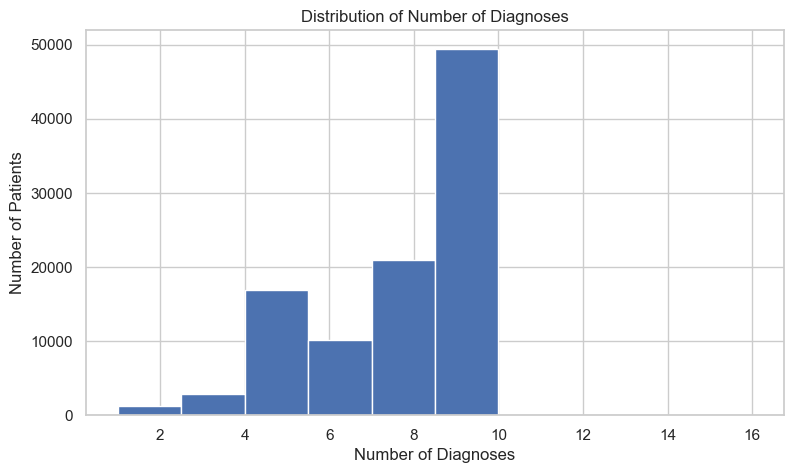

In [20]:
# Create a figure for the diagnosis distribution
plt.figure(figsize=(9, 5))

# Plot the distribution of the number of diagnoses
plt.hist(
    df["number_diagnoses"].dropna(),
    bins=10
)

# Add chart title
plt.title("Distribution of Number of Diagnoses")

# Add x-axis label
plt.xlabel("Number of Diagnoses")

# Add y-axis label
plt.ylabel("Number of Patients")

# Display the chart
plt.show()

# Diagnosis vs Readmission

In [21]:
# Calculate the average 30-day readmission rate for each diagnosis count
diagnosis_readmission_rate = (
    df.groupby("number_diagnoses")["readmitted_binary"].mean() * 100
)

# Display the calculated readmission rates
print("Readmission Rate by Number of Diagnoses:")
print(diagnosis_readmission_rate.round(2))

Readmission Rate by Number of Diagnoses:
number_diagnoses
1      5.94
2      6.06
3      7.37
4      8.25
5      9.15
6     10.41
7     10.77
8     11.81
9     12.38
10    17.65
11    27.27
12    11.11
13    18.75
14    14.29
15    20.00
16     8.89
Name: readmitted_binary, dtype: float64


#  Diagnosis Boxplot

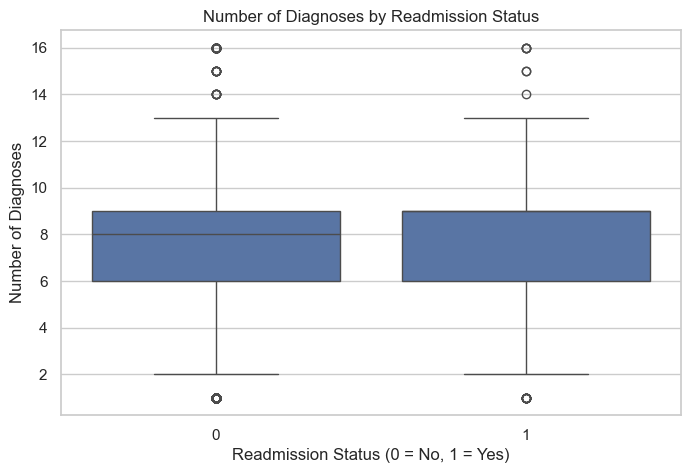

In [22]:
# Create a figure for comparing diagnosis counts between target classes
plt.figure(figsize=(8, 5))

# Create the boxplot
sns.boxplot(
    x="readmitted_binary",
    y="number_diagnoses",
    data=df
)

# Add chart title
plt.title("Number of Diagnoses by Readmission Status")

# Add x-axis label
plt.xlabel("Readmission Status (0 = No, 1 = Yes)")

# Add y-axis label
plt.ylabel("Number of Diagnoses")

# Display the chart
plt.show()

# 5. Number of Medications Analysis

The `num_medications` variable represents the number of medications
administered to the patient.

We will analyze its relationship with 30-day readmission.

# Medication Statistics

In [23]:
# Display descriptive statistics for the number of medications
print("Number of Medications Statistics:")

# Calculate and display summary statistics
print(df["num_medications"].describe())

Number of Medications Statistics:
count    101766.000000
mean         16.021844
std           8.127566
min           1.000000
25%          10.000000
50%          15.000000
75%          20.000000
max          81.000000
Name: num_medications, dtype: float64


# Medication vs Readmission

In [24]:
# Calculate the average readmission rate for each medication count
medication_readmission_rate = (
    df.groupby("num_medications")["readmitted_binary"].mean() * 100
)

# Display the calculated readmission rates
print("Readmission Rate by Number of Medications:")

# Show the first 20 values to keep the output readable
print(medication_readmission_rate.head(20).round(2))

Readmission Rate by Number of Medications:
num_medications
1      4.20
2      8.30
3      7.22
4      8.05
5      7.44
6      8.48
7      8.75
8      9.56
9      9.81
10     9.97
11    10.37
12    10.78
13    10.99
14    10.76
15    11.65
16    11.49
17    12.16
18    12.18
19    12.24
20    13.11
Name: readmitted_binary, dtype: float64


# Medication Plot

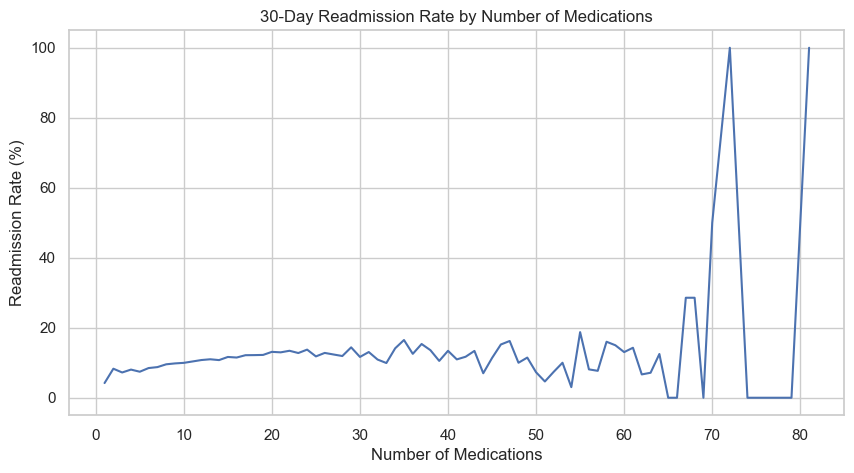

In [25]:
# Create a figure for the medication-readmission relationship
plt.figure(figsize=(10, 5))

# Plot medication count against readmission rate
plt.plot(
    medication_readmission_rate.index,
    medication_readmission_rate.values
)

# Add chart title
plt.title("30-Day Readmission Rate by Number of Medications")

# Add x-axis label
plt.xlabel("Number of Medications")

# Add y-axis label
plt.ylabel("Readmission Rate (%)")

# Display the chart
plt.show()

# 6. Previous Healthcare Visits

Previous healthcare utilization may provide useful information about
a patient's healthcare history.

The dataset contains:
- `number_inpatient` — previous inpatient visits
- `number_emergency` — previous emergency visits
- `number_outpatient` — previous outpatient visits

We will examine their relationship with 30-day readmission.

# Previous Inpatient Visits

In [26]:
# Calculate the average readmission rate for each number of previous inpatient visits
inpatient_readmission_rate = (
    df.groupby("number_inpatient")["readmitted_binary"].mean() * 100
)

# Display the calculated readmission rates
print("Readmission Rate by Previous Inpatient Visits:")

# Display the results
print(inpatient_readmission_rate.round(2))

Readmission Rate by Previous Inpatient Visits:
number_inpatient
0       8.44
1      12.92
2      17.43
3      20.29
4      23.61
5      31.40
6      34.58
7      35.45
8      44.37
9      42.34
10     42.62
11     67.35
12     50.00
13     50.00
14     40.00
15    100.00
16     33.33
17    100.00
18      0.00
19     50.00
21    100.00
Name: readmitted_binary, dtype: float64


# Inpatient Visit Plot

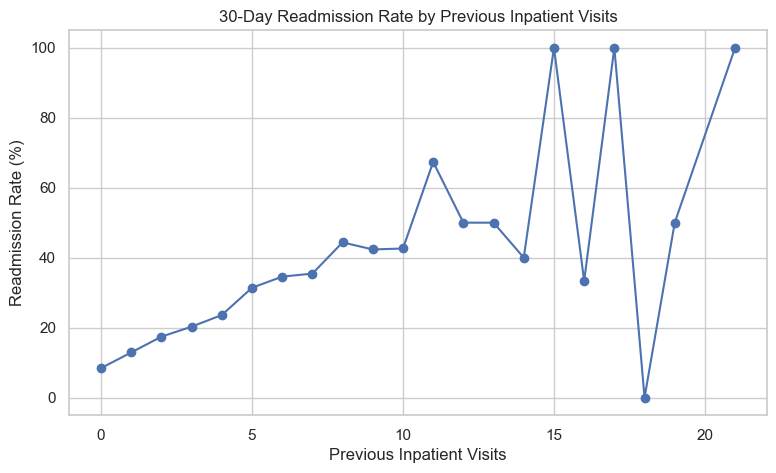

In [27]:
# Create a figure for inpatient visit analysis
plt.figure(figsize=(9, 5))

# Plot previous inpatient visits against readmission rate
plt.plot(
    inpatient_readmission_rate.index,
    inpatient_readmission_rate.values,
    marker="o"
)

# Add chart title
plt.title("30-Day Readmission Rate by Previous Inpatient Visits")

# Add x-axis label
plt.xlabel("Previous Inpatient Visits")

# Add y-axis label
plt.ylabel("Readmission Rate (%)")

# Display the chart
plt.show()

# Previous Emergency Visits

In [28]:
# Calculate the average readmission rate for each number of emergency visits
emergency_readmission_rate = (
    df.groupby("number_emergency")["readmitted_binary"].mean() * 100
)

# Display the calculated readmission rates
print("Readmission Rate by Previous Emergency Visits:")

# Display the results
print(emergency_readmission_rate.round(2))

Readmission Rate by Previous Emergency Visits:
number_emergency
0      10.47
1      14.35
2      18.27
3      20.28
4      30.75
5      24.48
6      23.40
7      26.03
8      32.00
9      36.36
10     35.29
11     21.74
12     20.00
13     33.33
14      0.00
15     33.33
16     40.00
18     20.00
19     50.00
20     50.00
21     50.00
22     50.00
24      0.00
25      0.00
28    100.00
29      0.00
37      0.00
42      0.00
46      0.00
54      0.00
63      0.00
64    100.00
76      0.00
Name: readmitted_binary, dtype: float64


# Emergency Visit Plot

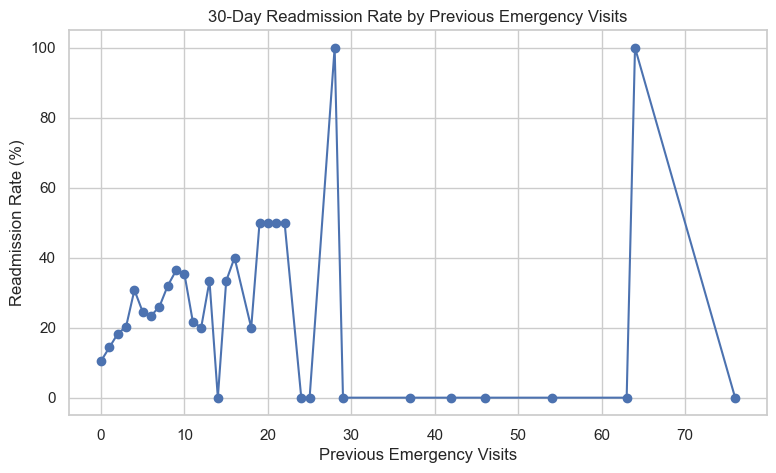

In [29]:
# Create a figure for emergency visit analysis
plt.figure(figsize=(9, 5))

# Plot emergency visits against readmission rate
plt.plot(
    emergency_readmission_rate.index,
    emergency_readmission_rate.values,
    marker="o"
)

# Add chart title
plt.title("30-Day Readmission Rate by Previous Emergency Visits")

# Add x-axis label
plt.xlabel("Previous Emergency Visits")

# Add y-axis label
plt.ylabel("Readmission Rate (%)")

# Display the chart
plt.show()

# Code: Previous Outpatient Visits

In [30]:
# Calculate the average readmission rate for each number of outpatient visits
outpatient_readmission_rate = (
    df.groupby("number_outpatient")["readmitted_binary"].mean() * 100
)

# Display the calculated readmission rates
print("Readmission Rate by Previous Outpatient Visits:")

# Display the results
print(outpatient_readmission_rate.round(2))

Readmission Rate by Previous Outpatient Visits:
number_outpatient
0      10.67
1      13.92
2      13.75
3      12.29
4      15.10
5      11.82
6      13.20
7      15.48
8       5.10
9      15.66
10      8.77
11     14.29
12     20.00
13     19.35
14     17.86
15     10.00
16      0.00
17     12.50
18      0.00
19     33.33
20      0.00
21      0.00
22     20.00
23     50.00
24      0.00
25      0.00
26      0.00
27      0.00
28      0.00
29      0.00
33      0.00
34      0.00
35      0.00
36      0.00
37      0.00
38      0.00
39      0.00
40    100.00
42      0.00
Name: readmitted_binary, dtype: float64


# Outpatient Visit Plot

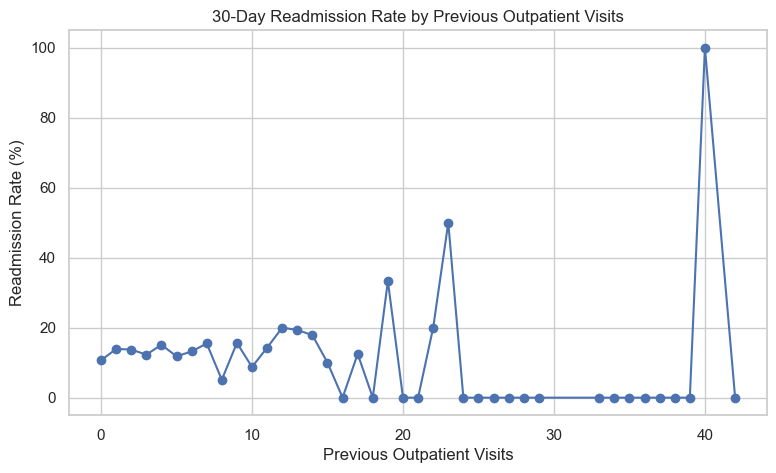

In [31]:
# Create a figure for outpatient visit analysis
plt.figure(figsize=(9, 5))

# Plot outpatient visits against readmission rate
plt.plot(
    outpatient_readmission_rate.index,
    outpatient_readmission_rate.values,
    marker="o"
)

# Add chart title
plt.title("30-Day Readmission Rate by Previous Outpatient Visits")

# Add x-axis label
plt.xlabel("Previous Outpatient Visits")

# Add y-axis label
plt.ylabel("Readmission Rate (%)")

# Display the chart
plt.show()

# 7. Diabetes Medication Analysis

The `diabetesMed` variable indicates whether diabetes medication
was prescribed or administered.

We will compare:
- Distribution of medication status
- 30-day readmission rate for each category

# Diabetes Medication Distribution

In [32]:
# Count the number of patients in each diabetes medication category
diabetes_med_counts = df["diabetesMed"].value_counts(dropna=False)

# Display the category counts
print("Diabetes Medication Distribution:")
print(diabetes_med_counts)

Diabetes Medication Distribution:
diabetesMed
Yes    78363
No     23403
Name: count, dtype: int64


# Diabetes Medication Plot

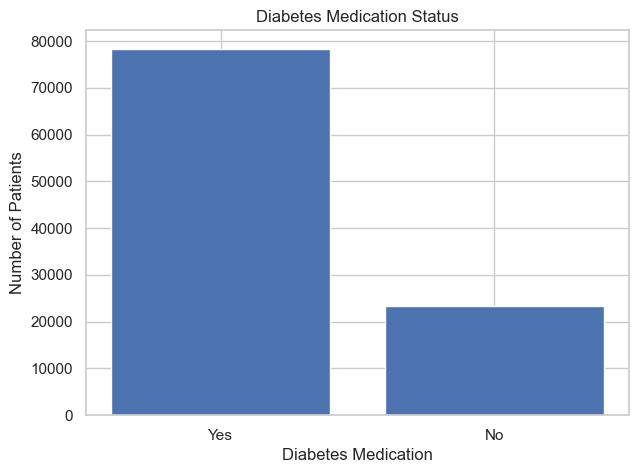

In [33]:
# Create a figure for diabetes medication distribution
plt.figure(figsize=(7, 5))

# Plot the number of patients in each medication category
plt.bar(
    diabetes_med_counts.index.astype(str),
    diabetes_med_counts.values
)

# Add chart title
plt.title("Diabetes Medication Status")

# Add x-axis label
plt.xlabel("Diabetes Medication")

# Add y-axis label
plt.ylabel("Number of Patients")

# Display the chart
plt.show()

# Readmission by Diabetes Medication

In [34]:
# Calculate the average readmission rate for each diabetes medication category
diabetes_med_readmission_rate = (
    df.groupby("diabetesMed", dropna=False)["readmitted_binary"].mean() * 100
)

# Display the calculated readmission rates
print("30-Day Readmission Rate by Diabetes Medication:")

# Display the results
print(diabetes_med_readmission_rate.round(2))

30-Day Readmission Rate by Diabetes Medication:
diabetesMed
No      9.60
Yes    11.63
Name: readmitted_binary, dtype: float64


# Diabetes Medication Readmission Plot

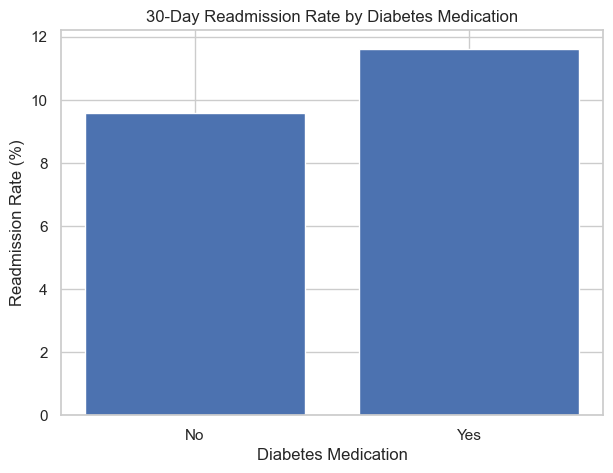

In [35]:
# Create a figure for the medication-readmission relationship
plt.figure(figsize=(7, 5))

# Plot the readmission rate for each medication category
plt.bar(
    diabetes_med_readmission_rate.index.astype(str),
    diabetes_med_readmission_rate.values
)

# Add chart title
plt.title("30-Day Readmission Rate by Diabetes Medication")

# Add x-axis label
plt.xlabel("Diabetes Medication")

# Add y-axis label
plt.ylabel("Readmission Rate (%)")

# Display the chart
plt.show()

# 8. Numerical Feature Correlation Analysis

Correlation analysis helps us understand the strength and direction
of relationships between numerical variables.

The correlation coefficient ranges from -1 to +1:

- +1 = Strong positive relationship
- 0 = No linear relationship
- -1 = Strong negative relationship

Correlation does not imply causation.

# Select Numerical Features

In [36]:
# Define important numerical features for correlation analysis
numerical_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "readmitted_binary"
]

# Select the numerical features from the dataset
numeric_df = df[numerical_features].copy()

# Display the first five rows
numeric_df.head()

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted_binary
0,1,41,0,1,0,0,0,1,0
1,3,59,0,18,0,0,0,9,0
2,2,11,5,13,2,0,1,6,0
3,2,44,1,16,0,0,0,7,0
4,1,51,0,8,0,0,0,5,0


# Correlation Matrix

In [37]:
# Calculate the Pearson correlation between numerical features
correlation_matrix = numeric_df.corr()

# Display the complete correlation matrix
correlation_matrix.round(3)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted_binary
time_in_hospital,1.000,0.318,0.191,0.466,-0.009,-0.010,0.074,0.220,0.044
num_lab_procedures,0.318,1.000,0.058,0.268,-0.008,-0.002,0.039,0.153,0.020
num_procedures,0.191,0.058,1.000,0.386,-0.025,-0.038,-0.066,0.074,-0.012
num_medications,0.466,0.268,0.386,1.000,0.045,0.013,0.064,0.262,0.038
number_outpatient,-0.009,-0.008,-0.025,0.045,1.000,0.091,0.107,0.094,0.019
number_emergency,-0.010,-0.002,-0.038,0.013,0.091,1.000,0.267,0.056,0.061
number_inpatient,0.074,0.039,-0.066,0.064,0.107,0.267,1.000,0.105,0.165
number_diagnoses,0.220,0.153,0.074,0.262,0.094,0.056,0.105,1.000,0.050
readmitted_binary,0.044,0.020,-0.012,0.038,0.019,0.061,0.165,0.050,1.000


# Correlation Heatmap

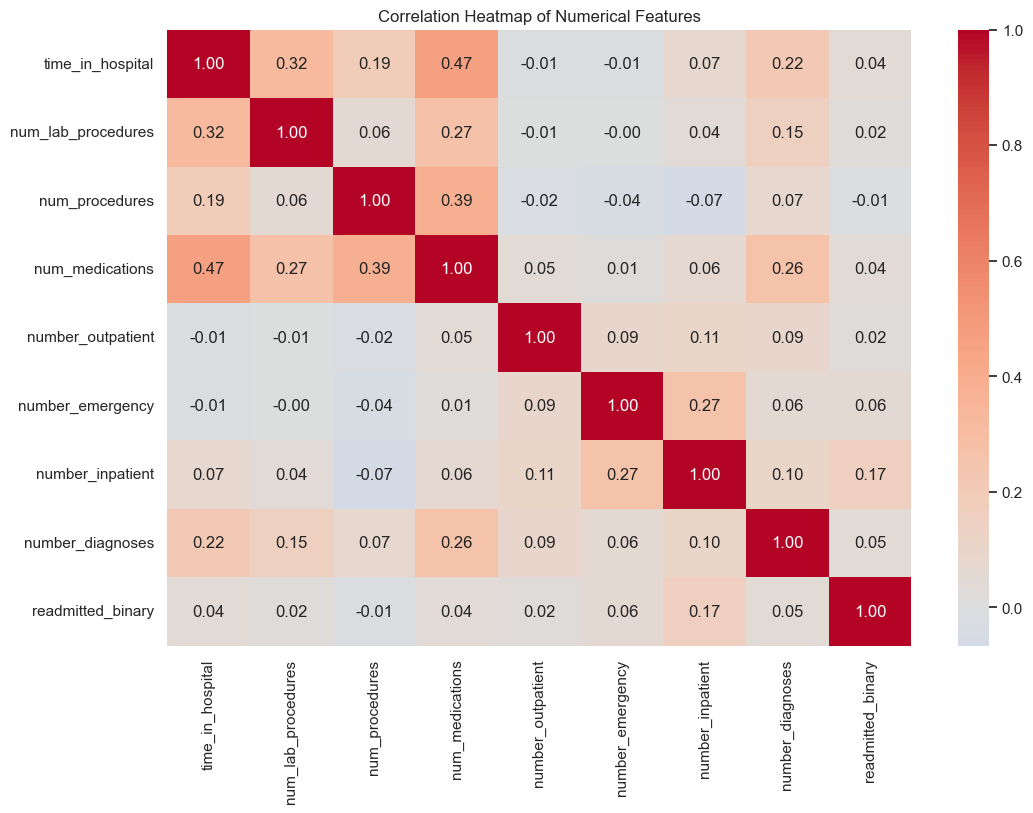

In [38]:
# Create a larger figure for the correlation heatmap
plt.figure(figsize=(12, 8))

# Create a heatmap using the correlation matrix
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

# Add chart title
plt.title("Correlation Heatmap of Numerical Features")

# Display the heatmap
plt.show()

# Correlation with Target

In [39]:
# Select only correlations related to the readmission target
target_correlations = correlation_matrix["readmitted_binary"].sort_values(
    ascending=False
)

# Display the correlation of each numerical feature with the target
print("Correlation with 30-Day Readmission Target:")

# Round the values for easier interpretation
print(target_correlations.round(3))

Correlation with 30-Day Readmission Target:
readmitted_binary     1.000
number_inpatient      0.165
number_emergency      0.061
number_diagnoses      0.050
time_in_hospital      0.044
num_medications       0.038
num_lab_procedures    0.020
number_outpatient     0.019
num_procedures       -0.012
Name: readmitted_binary, dtype: float64


# 9. EDA Observations

Based on the exploratory analysis:

1. The target variable is imbalanced, with fewer patients being readmitted
   within 30 days.

2. The distribution of patients varies across different age groups.

3. Hospital stay duration varies across patients and can be compared
   between readmission groups.

4. The number of diagnoses provides information about patient complexity.

5. The number of medications varies across patients and can be examined
   in relation to readmission.

6. Previous inpatient, emergency, and outpatient visits show different
   readmission patterns.

7. Diabetes medication status also shows differences across patient groups.

8. Correlation analysis provides an initial understanding of relationships
   between numerical variables.

### Important

These observations represent statistical associations in the dataset.
They do not prove that a particular variable causes hospital readmission.

# Create EDA Summary

In [40]:
# Create a summary dictionary containing important EDA information
eda_summary = {
    "Total Patients": len(df),
    "Total Features": df.shape[1],
    "30-Day Readmission Cases": int(df["readmitted_binary"].sum()),
    "30-Day Readmission Rate (%)": round(
        df["readmitted_binary"].mean() * 100,
        2
    ),
    "Average Hospital Stay (Days)": round(
        df["time_in_hospital"].mean(),
        2
    ),
    "Average Number of Medications": round(
        df["num_medications"].mean(),
        2
    ),
    "Average Number of Diagnoses": round(
        df["number_diagnoses"].mean(),
        2
    )
}

# Convert the summary dictionary into a DataFrame
eda_summary_df = pd.DataFrame(
    eda_summary.items(),
    columns=["Metric", "Value"]
)

# Display the final EDA summary
eda_summary_df

,Metric,Value
0,Total Patients,101766.00
1,Total Features,51.00
2,30-Day Readmission Cases,11357.00
3,30-Day Readmission Rate (%),11.16
4,Average Hospital Stay (Days),4.40
5,Average Number of Medications,16.02
6,Average Number of Diagnoses,7.42


# Conclusion

Exploratory Data Analysis has been completed successfully.

The analysis helped us understand:
- Target class imbalance
- Patient age distribution
- Hospital stay patterns
- Number of diagnoses
- Medication usage
- Previous healthcare visits
- Diabetes medication status
- Numerical feature correlations

The insights obtained from EDA will be used in the next stage:
**Feature Engineering**.

The next notebook will transform the available variables into useful
machine-learning features while maintaining a reproducible workflow.

# Final Completion Check

In [41]:
# Print a message confirming that the EDA notebook has completed
print("==========================================")

# Confirm that the EDA process finished successfully
print("EDA Notebook Completed Successfully")

# Display the total number of patients analyzed
print("Total Patients:", len(df))

# Display the total number of columns currently available
print("Total Columns:", df.shape[1])

# Display the number of 30-day readmission cases
print(
    "30-Day Readmission Cases:",
    int(df["readmitted_binary"].sum())
)

# Display the 30-day readmission percentage
print(
    "30-Day Readmission Rate:",
    round(df["readmitted_binary"].mean() * 100, 2),
    "%"
)

# Print a closing separator
print("==========================================")

EDA Notebook Completed Successfully
Total Patients: 101766
Total Columns: 51
30-Day Readmission Cases: 11357
30-Day Readmission Rate: 11.16 %
